# Build and validate a state-aware mining schedule

**Question:** How does a policy choose among blocks that remain feasible at each decision?

**Level:** A worked method and evidence analysis with an explicit claim boundary.

## Objectives

This worked lesson traces a small synthetic graph through the state-aware scheduling contract. You will generate a repeatable instance, inspect named node features, fit a train-only normalizer, distinguish precedence readiness from full resource feasibility, advance a transparent policy, and validate the exported assignments from the original instance. The exercise focuses on decisions that can be audited one state at a time. It does not train a neural network, estimate performance on unseen deposits, or represent an operating mine. Treat the generated values as method-development fixtures and keep the stated resource units with every comparison.

## Setup

Run from the repository root with the exact notebook pins below. The lesson imports the product's graph generator and schedule primitives; it does not redefine those functions. No network access, model weights, private data, or training job is needed. A fixed seed and generator version make the input reproducible. Package versions matter because changing the generator, solver, or numerical library can alter schedules. If the environment does not match the pins, stop and prepare the declared environment instead of substituting another implementation.

Environment install command:

```bash
python -m pip install oreblocks==0.6.6 numpy==2.5.1 matplotlib==3.11.2
```

In [1]:
# Import pinned packages and the product's public frontier primitives.
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data-pipeline").is_dir())
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.frontier_data import generate_graph, FEATURE_NAMES
from pipeline.model.frontier_policy import (
    FeatureNormalizer,
    feasible_frontier,
    precedence_frontier,
    replay_frontier_policy,
    validate_schedule,
)
import importlib.metadata

print({name: importlib.metadata.version(name) for name in ("oreblocks", "numpy", "matplotlib")})


{'oreblocks': '0.6.6', 'numpy': '2.5.1', 'matplotlib': '3.11.2'}


## Data

Each generated block has one canonical row, a finite economic value, non-negative consumption in mining and processing resources, an acyclic set of immediate predecessors, and a capacity row for each period. Edges point from prerequisite to dependent block. The generator also returns a named feature matrix whose column order is part of its contract. The example uses crosscut geometry and a fixed size. It is synthetic: neither its grades nor its values are drawn from MineLib or licensed operations. Keep identifiers, labels, outcomes, and split membership outside the feature matrix.

Generate the fitting rows separately from the graph used for inspection.

In [2]:
# Generate separate training graphs and one inspectable decision graph.
train_graphs = [generate_graph(seed, "benched", 64, periods=8) for seed in range(10_101, 10_111)]
case = generate_graph(20_007, "crosscut", 96, periods=8)
train_matrix = np.vstack([g.node_features for g in train_graphs])
normalizer = FeatureNormalizer.fit(train_matrix, FEATURE_NAMES, declared_features=FEATURE_NAMES)
case_features = normalizer.transform(case.node_features, FEATURE_NAMES)
print(
    {
        "generator": case.family_parameters,
        "features": FEATURE_NAMES,
        "shape": case_features.shape,
        "normalizer_sha256": normalizer.sha256,
    }
)
assert np.isfinite(case_features).all()


{'generator': 'frontier-graphs/1.0.0:crosscut:size=96:periods=8:v1', 'features': ('value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count'), 'shape': (96, 7), 'normalizer_sha256': '6e903528660b420aaad208f787c997402decb7381e82fbf50b0d1171f7778e8e'}


Construct a second graph with a different family so the normalizer is not fitted on its evaluation rows.

In [3]:
# Generate the separate graph that will be inspected and scheduled.
case = generate_graph(20_007, "crosscut", 96, periods=8)
print(
    {"generator": case.family_parameters, "blocks": len(case.instance.values), "feature_names": FEATURE_NAMES}
)


{'generator': 'frontier-graphs/1.0.0:crosscut:size=96:periods=8:v1', 'blocks': 96, 'feature_names': ('value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count')}


## Method

At period t, the precedence frontier contains unassigned blocks whose prerequisites have already been scheduled by t. The resource filter subtracts current-period use from each capacity and keeps a block only when its entire resource vector fits. An action may therefore be graph-ready but still excluded by mining or processing capacity. Explicit stop-period and stop-schedule actions make an empty frontier and deliberate termination representable. In a learned actor, graph messages summarize local structure, the dynamic state describes the current period and remaining resources, and a mask excludes inadmissible block logits before selection. The transparent score in this lesson is only a deterministic probe of that interface; it is not the trained actor.

A review should also compare the prior assignment prefix with the remaining capacity vector after every period transition. This reveals whether a candidate disappeared because a prerequisite was unscheduled or because one specific resource was binding. The distinction is essential when a model repeatedly chooses stop-period or returns a short plan. A feasible action set guarantees only that exposed block actions fit the declared state; it does not guarantee that the policy will choose a valuable action. Record the binding dimension and current period in debugging output. Such a trace makes an empty frontier explainable and helps separate a narrow resource budget from an error in predecessor indexing. These diagnostics improve engineering clarity without adding a claim about economic quality.

$$E_t=\{b
otin A:P_b\subseteq\{i:p_i\leq t\}\}.$$

$$F_t=\{b\in E_t:r_b\leq C_t-u_t\}.$$

The first set enforces prerequisites; the second applies every resource limit to residual capacity.

Measure the two candidate sets before selecting an action.

In [4]:
# Compare structural eligibility with full-vector resource feasibility at each period.
instance = case.instance
ready = precedence_frontier(instance, (), 0)
feasible = feasible_frontier(instance, (), 0)
print(
    {
        "period_zero_ready": len(ready),
        "period_zero_feasible": len(feasible),
        "capacity_removed": len(ready) - len(feasible),
    }
)
assert set(feasible).issubset(ready)


{'period_zero_ready': 1, 'period_zero_feasible': 1, 'capacity_removed': 0}


Replay a transparent score and independently recalculate the schedule value.

In [5]:
# Replay a transparent value score through the same feasibility-constrained transition.
score = lambda b, p, a: float(instance.values[b]) if b >= 0 else -1.0
result = replay_frontier_policy(instance, score, tonnage=case.tonnage)
independent_value = validate_schedule(instance, result.assignments)
print(
    {
        "assignments": len(result.assignments),
        "independent_npv": independent_value,
        "stop_reason": result.stopped,
        "tonnage_coverage": result.tonnage_coverage,
        "positive_value_coverage": result.positive_value_coverage,
    }
)


{'assignments': 21, 'independent_npv': 6.5810534023261145, 'stop_reason': 'horizon-complete', 'tonnage_coverage': 0.2030469209123082, 'positive_value_coverage': 0.19394082509847316}


Reconstruct each decision from the prior assignments to check mask eligibility.

In [6]:
# Reconstruct each decision's candidate counts from its prior assignment prefix.
prefix = []
ready_counts = []
feasible_counts = []
for assignment in result.assignments:
    ready_counts.append(len(precedence_frontier(instance, prefix, assignment.period)))
    feasible_counts.append(len(feasible_frontier(instance, prefix, assignment.period)))
    prefix.append(assignment)
assert len(prefix) == len(result.assignments)


## Comparison

The first view compares the count of graph-ready choices with the smaller feasible action set during replay. A difference is attributable to resource checks because the same assignment prefix feeds both calls. The second view compares two resource loads against their separate period capacities. Those units must not be collapsed into one total: enough mining capacity does not imply enough processing capacity. We also contrast raw and standardized features to show why normalization is fitted on training rows and then reused unchanged. No performance ranking is inferred from the plotted counts.

## Evidence

Evidence is local and mechanical. The output records the seed, generator contract, feature names, normalizer digest, action counts, assignments, independent objective, resource loads, and coverage. Assertions confirm the standardized values are finite, every replayed block was admissible before assignment, and the independent validator accepts the complete schedule. The figures are generated from these live objects. Passing these checks establishes one reproducible software example; it does not establish feasibility for a different input, training quality, economic value, or transfer beyond this graph.

This figure is computed from states visited by the replay. The following text reads the visible change in available actions.

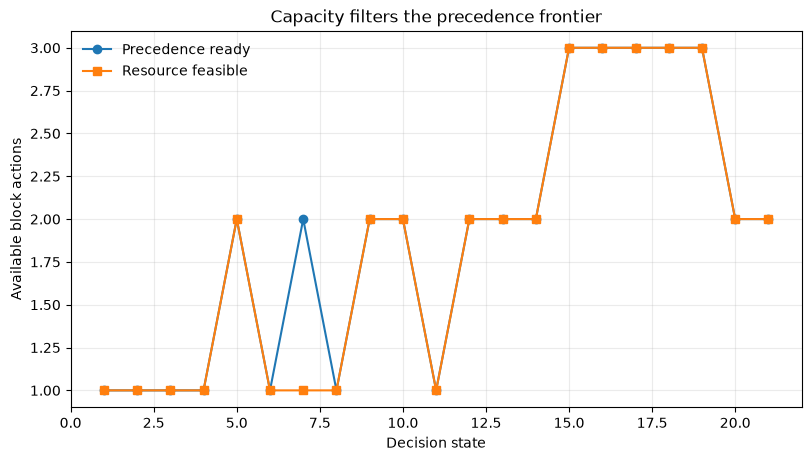

In [7]:
# Plot action-set contraction for the replayed states.
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
steps = np.arange(1, len(ready_counts) + 1)
ax.plot(steps, ready_counts, marker="o", label="Precedence ready")
ax.plot(steps, feasible_counts, marker="s", label="Resource feasible")
ax.set(
    xlabel="Decision state",
    ylabel="Available block actions",
    title="Capacity filters the precedence frontier",
)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.show()


Follow the same state with both resource dimensions shown separately. The lines are derived from the schedule and its original capacity matrix. A load curve below its limit shows unused capacity in that period; it does not show whether another period or the precedence graph prevented additional work. Read the two panels together with the stop reason and coverage values printed above.

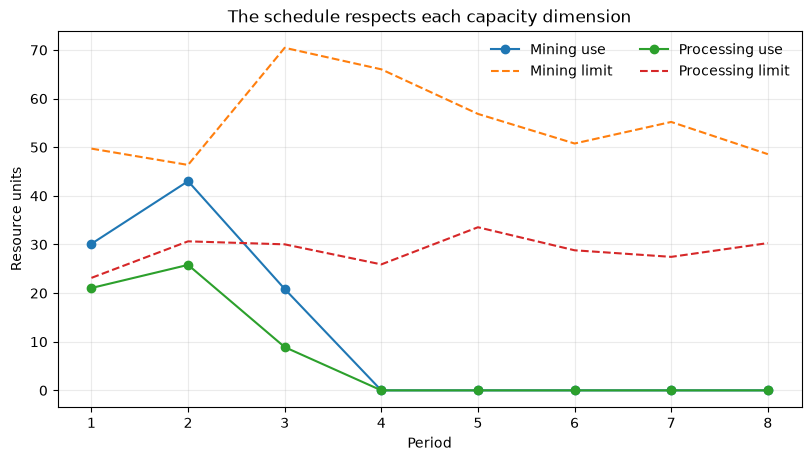

In [8]:
# Compare both resource loads with their own period capacities.
usage = np.zeros_like(instance.capacities)
for assignment in result.assignments:
    usage[assignment.period] += instance.resources[assignment.block]
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
periods = np.arange(1, len(instance.capacities) + 1)
for resource, name in enumerate(("Mining", "Processing")):
    ax.plot(periods, usage[:, resource], marker="o", label=f"{name} use")
    ax.plot(periods, instance.capacities[:, resource], linestyle="--", label=f"{name} limit")
ax.set(xlabel="Period", ylabel="Resource units", title="The schedule respects each capacity dimension")
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=2)
plt.show()


The capacity sweep holds values, graph edges, feature vectors, and the transparent score fixed. Coverage stays unchanged over these four multipliers while discounted NPV varies with block timing. That response belongs to this generated instance only. Treat the two panels as local sensitivity diagnostics, not a cross-case result.

{'factors': [0.7, 0.85, 1.0, 1.15], 'coverage_npv': [(0.19394082509847316, 6.260983374702888), (0.19394082509847316, 6.402517817175093), (0.19394082509847316, 6.5810534023261145), (0.19394082509847316, 6.5393945154820035)]}


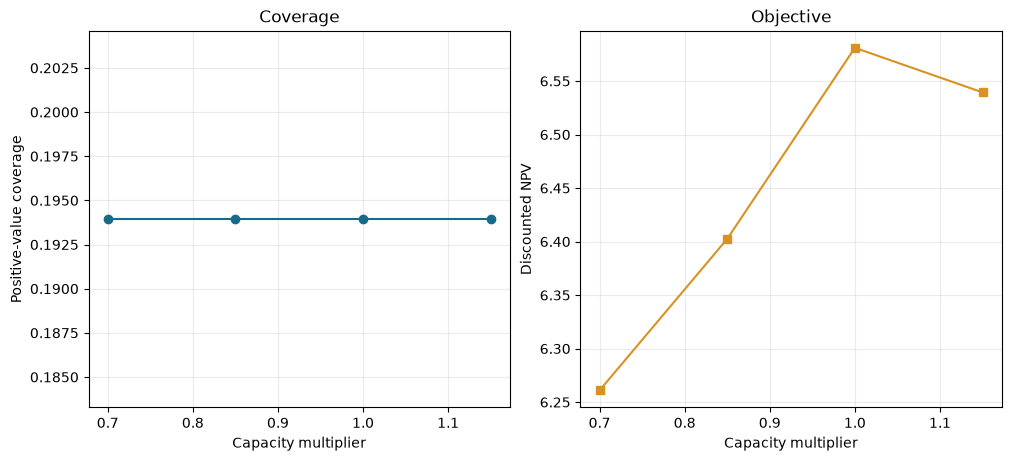

In [9]:
# Re-run the same score over a declared uniform capacity sweep.
from dataclasses import replace

factors = np.array([0.70, 0.85, 1.00, 1.15])
sweep = []
for factor in factors:
    variant = replace(instance, capacities=instance.capacities * factor)
    replay = replay_frontier_policy(variant, score, tonnage=case.tonnage)
    sweep.append((replay.positive_value_coverage, replay.npv))
print({"factors": factors.tolist(), "coverage_npv": sweep})
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
axes[0].plot(factors, [row[0] for row in sweep], marker="o", color="#176B87")
axes[0].set(xlabel="Capacity multiplier", ylabel="Positive-value coverage", title="Coverage")
axes[1].plot(factors, [row[1] for row in sweep], marker="s", color="#D79222")
axes[1].set(xlabel="Capacity multiplier", ylabel="Discounted NPV", title="Objective")
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()


Read this curve as the response of one fixed synthetic graph and score to the declared capacity multipliers. It shows how the resource budget changes positive-value coverage for this example; it does not compare policies or estimate behavior across deposits. The printed table also retains objective values because discounted value may move differently from coverage.

## Results

Interpret the mask count as the number of actions the policy can legally choose at that moment, not as a score. Interpret objective and coverage together: a feasible partial schedule can leave positive-value blocks and tonnage unassigned. The validator recomputes uniqueness, precedence, all capacity dimensions, and discounted value from the original instance, so a previously valid action mask does not excuse a corrupted export. This is the end-to-end method mechanics demonstration. Empirical claims belong to a separate frozen evaluation, and the accompanying evidence lesson reports why the current diagnostic cannot serve as one.

**Answer:** The 96-block graph supports the stated calculations, with its validation-only status limiting the conclusion.

## Summary

The method boundary is clear: graph structure and partial schedule state inform action scores, the feasibility mask restricts block choices, and an independent validator checks the exported result. A train-only normalizer is hashed so inference uses exactly the same feature order and scale. When adapting the pipeline, preserve canonical IDs, source units, split provenance, stop reasons, and both coverage measures. Never infer that an empty action set is a model failure until precedence and each residual resource have been inspected. This lesson supplies an auditable mechanics example, not a comparison or deployment recommendation.

### Sensitivity and limits

The capacity sweep above varies the full capacity matrix by one declared multiplier. This is a local sensitivity check, not a robustness study. To inspect which resource drives a decision, vary mining and processing columns separately while holding all other columns fixed; then repeat with a small factorial grid to expose interactions. Preserve the original instance and create a new immutable variant for each run. Record the multiplier, changed columns, stopping reason, objective, tonnage coverage, positive-value coverage, and validator result in a tidy case table. Plot each output against the varied parameter and retain the zero-action cases. If a metric changes discontinuously, inspect the action trace around the threshold: precedence can make a small resource change unlock a chain of blocks.

Repeat the exercise across several graph families and sizes before describing a pattern. Use a fixed seed set for paired comparisons and separate the seed set used to tune a policy from the set used to summarize its behavior. Report the full distribution and the number of attempted cases, including failed generations and validator rejections. A single generated graph cannot estimate uncertainty or establish stability. This notebook's graph is deliberately synthetic, and the deterministic score is a teaching probe. Neither the sweep nor the schedule validator measures geological realism, operating cost, reserve confidence, or mine-plan acceptability. Those questions need domain data, an approved economic model, and independent review.

For a useful diagnostic table, retain one row for every combination of graph, resource variant, and policy configuration. Store the raw capacity vector as well as the multiplier so another analyst can reconstruct the experiment. Compare decision traces to identify where the first action divergence occurs; aggregate objective differences alone can conceal a changed period assignment or a binding predecessor. Check the validator against deliberately perturbed schedules, including duplicate blocks, reversed precedence, and over-capacity assignments, and confirm that each violation is reported. These are software fault checks, not evidence that the model generalizes. Keep development cases separate from any later frozen assessment and log all protocol changes before inspecting its outcomes. Also inspect whether ties in the score are resolved deterministically, whether stop actions can be selected when blocks remain feasible, and whether discount periods follow the declared indexing convention. Small contract mismatches can change the schedule while every individual assignment still appears legal. Save the complete configuration with each trace so a reviewer can tell whether two runs differ because of capacity, scoring, or an implementation version.

### Use with your own data

Start with a versioned input contract. Keep one stable block identifier per row; declare units for value, tonnage, mining capacity, processing capacity, and discount period; and store provenance for each source field. Validate finite values, nonnegative resource use, unique identifiers, acyclic precedence edges, and complete capacity rows before constructing a graph. Resolve duplicated rows and missing fields through documented rules rather than silent imputation. Keep economic labels and outcome-derived features out of model inputs, and preserve the mapping back to source records in a controlled environment.

Build partitions by deposit or another independent geological grouping when that matches the intended use. Freeze the manifest before model selection, fit feature scaling only on training rows, and reuse its feature order and digest at inference. Run a simple transparent baseline on the same cases and retain paired per-case outputs. For every policy, persist the input hash, configuration, seed, selected checkpoint, action trace, stop reason, validator findings, objective, and both coverage measures. Write each case atomically so an interrupted evaluation is resumable without rerunning completed cases. Have an independent reviewer check the validator and unit conversions before any results guide a real planning decision.

## References

The clipped policy-gradient objective supplies background for the training algorithm, while the PhaseFlow repository documents its finite-horizon action contract, preprocessing, and schedule validator. These references do not transfer performance claims to the synthetic example. All numeric outputs are computed when the notebook runs.

- Policy-gradient method: https://arxiv.org/abs/1707.06347
- Adaptive optimizer: https://arxiv.org/abs/1412.6980
- Open-pit scheduling formulation: https://doi.org/10.1287/inte.2013.0731
- Implementation and records: https://github.com/fsantibanezleal/CAOS_PhaseFlow